# Phishing Website Detection Using Machine Learning
**Course:** Information Security Lab | **Group 9**
**Members:** Tanseer Haider, Hassan Ameer Ahmad, M. Arham

## Module 1: Project Setup and Dataset Understanding
**Goal:** Load the public UCI Phishing Websites dataset and understand it before training any model.

**Why this module?** A model is only as good as its data. We must know what the data is, what each feature means, and whether it has problems.

## Step 1: Install and import libraries

In [16]:
!pip install ucimlrepo -q

import pandas as pd
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo

print("Libraries ready")

Libraries ready


## Step 2: Load the dataset (UCI Phishing Websites, ID 327)

In [17]:
data = fetch_ucirepo(id=327)

X = data.data.features   #put the 30 features
y = data.data.targets    # the label (phishing or legitimate)

print("Dataset loaded from UCI")
# X holds the warning signs of each website and y holds the answer: phishing or legitimate.

Dataset loaded from UCI


## Step 3: Look at the data

In [18]:
print("Features (X) shape:", X.shape)
print("Label (y) shape:", y.shape)
print("Number of websites :", X.shape[0])
print("Number of features :", X.shape[1])
#The dataset has 11,055 websites, and each has 30 features and 1 label

Features (X) shape: (11055, 30)
Label (y) shape: (11055, 1)
Number of websites : 11055
Number of features : 30


In [19]:
# First 5 rows
X.head()

#shows the first 5 rows. Each row is one website, and each column is one warning sign.
# Row 0 has having_ip_address = -1, sslfinal_state = -1 and web_traffic = -1. These are phishing-like signs

,having_ip_address,url_length,shortining_service,having_at_symbol,double_slash_redirecting,prefix_suffix,having_sub_domain,sslfinal_state,domain_registration_length,favicon,...,rightclick,popupwindow,iframe,age_of_domain,dnsrecord,web_traffic,page_rank,google_index,links_pointing_to_page,statistical_report
0,-1,1,1,1,-1,-1,-1,-1,-1,1,...,1,1,1,-1,-1,-1,-1,1,1,-1
1,1,1,1,1,1,-1,0,1,-1,1,...,1,1,1,-1,-1,0,-1,1,1,1
2,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,1,-1,1,-1,1,0,-1
3,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,1,-1,-1,1,-1,1,-1,1
4,1,0,-1,1,1,-1,1,1,-1,1,...,1,-1,1,-1,-1,0,-1,1,1,1


In [28]:
# Column names
print(list(X.columns))
#It prints the 30 feature names, such as url_length, sslfinal_state and web_traffic.

['having_ip_address', 'url_length', 'shortining_service', 'having_at_symbol', 'double_slash_redirecting', 'prefix_suffix', 'having_sub_domain', 'sslfinal_state', 'domain_registration_length', 'favicon', 'port', 'https_token', 'request_url', 'url_of_anchor', 'links_in_tags', 'sfh', 'submitting_to_email', 'abnormal_url', 'redirect', 'on_mouseover', 'rightclick', 'popupwindow', 'iframe', 'age_of_domain', 'dnsrecord', 'web_traffic', 'page_rank', 'google_index', 'links_pointing_to_page', 'statistical_report']


In [21]:
# Data types
X.dtypes

#Every column is int64, meaning whole numbers

,0
having_ip_address,int64
url_length,int64
shortining_service,int64
having_at_symbol,int64
double_slash_redirecting,int64
prefix_suffix,int64
having_sub_domain,int64
sslfinal_state,int64
domain_registration_length,int64
favicon,int64


## Step 4: Check data quality

In [22]:
# 1) Missing values
print("Total missing values in features:", X.isnull().sum().sum())
print("Total missing values in label   :", y.isnull().sum().sum())

Total missing values in features: 0
Total missing values in label   : 0


In [23]:
# 2) Duplicate rows (same website pattern repeated)
full = pd.concat([X, y], axis=1) #joins the features and the label side by side
dups = full.duplicated().sum()
print("Duplicate rows:", dups)
print("Percentage    : {:.1f}%".format(dups / len(full) * 100))

Duplicate rows: 5206
Percentage    : 47.1%


result
 1    6157
-1    4898
Name: count, dtype: int64

result
 1    55.7
-1    44.3
Name: count, dtype: float64


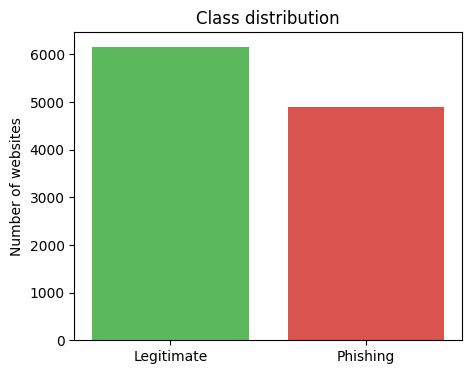

In [24]:
# 3) Class balance: how many phishing vs legitimate?
label_col = y.columns[0] #gets the label column’s name
counts = y[label_col].value_counts() #counts how many times each value (-1 and 1) appears
print(counts)
print()
print((counts / counts.sum() * 100).round(1)) #shows each class as a share of the total

names = {-1: "Phishing", 1: "Legitimate"}
colors = ["#5cb85c" if i == 1 else "#d9534f" for i in counts.index]

plt.figure(figsize=(5, 4))
plt.bar([names.get(i, str(i)) for i in counts.index], counts.values, color=colors) #draws the two counts: green for legitimate, red for phishing
plt.title("Class distribution")
plt.ylabel("Number of websites")
plt.show()

## Step 5: Understand the features

The 30 features are grouped into 4 groups:

| Group | What it looks at | Examples |
|---|---|---|
| Address bar based | The URL itself | having_IP_Address, URL_Length, having_At_Symbol |
| Domain based | Age and reputation of the domain | age_of_domain, DNSRecord, web_traffic |
| HTML / JavaScript based | The page code | Iframe, RightClick, popUpWidnow |
| Abnormal based | Strange behaviour of the page | Request_URL, URL_of_Anchor, SFH |

**What do the values mean?**
- **-1** = phishing-like (suspicious sign)
- **0** = suspicious (in between)
- **1** = legitimate-like (safe sign)

**The label:** `-1` = Phishing website, `1` = Legitimate website.

In [25]:
groups = {
    "Address bar based": ["having_ip_address", "url_length", "shortining_service", "having_at_symbol",
        "double_slash_redirecting", "prefix_suffix", "having_sub_domain", "sslfinal_state",
        "domain_registration_length", "favicon", "port", "https_token"],
    "Domain based": ["age_of_domain", "dnsrecord", "web_traffic", "page_rank", "google_index",
        "links_pointing_to_page", "statistical_report"],
    "HTML / JavaScript based": ["redirect", "on_mouseover", "rightclick", "popupwindow", "iframe"],
    "Abnormal based": ["request_url", "url_of_anchor", "links_in_tags", "sfh",
        "submitting_to_email", "abnormal_url"],
}

#A dictionary is a list of “group name , its features”.
#We put each of the 30 features into 1 of 4 groups

for g, cols in groups.items(): #The loop takes one group at a time (g is the group name and cols is its features)
    present = [c for c in cols if c in X.columns] #keeps only the features that really exist in our data
    print(f"{g} ({len(present)} features):") #counts them
    print("   ", present)
    print()  #show the group name, the count and the feature names

    #We split the 30 features into 4 groups. Address bar features look at the URL, domain features look at the domain’s age and reputation, HTML/JavaScript features look at the page code, and abnormal features look at suspicious behaviour. Together they make 30

Address bar based (12 features):
    ['having_ip_address', 'url_length', 'shortining_service', 'having_at_symbol', 'double_slash_redirecting', 'prefix_suffix', 'having_sub_domain', 'sslfinal_state', 'domain_registration_length', 'favicon', 'port', 'https_token']

Domain based (7 features):
    ['age_of_domain', 'dnsrecord', 'web_traffic', 'page_rank', 'google_index', 'links_pointing_to_page', 'statistical_report']

HTML / JavaScript based (5 features):
    ['redirect', 'on_mouseover', 'rightclick', 'popupwindow', 'iframe']

Abnormal based (6 features):
    ['request_url', 'url_of_anchor', 'links_in_tags', 'sfh', 'submitting_to_email', 'abnormal_url']



In [26]:
# What values does each feature take? (-1, 0, 1)
for col in X.columns:
    print(f"{col:30s} -> {[int(v) for v in sorted(X[col].unique())]}")
    #X[col].unique() finds the different values that column has
    #sorted(...) puts them in order, and int(v) makes them plain numbers
    #We checked what values each feature takes. All of them use only -1, 0 and 1. Most have two values, 8 have three, and redirect has only 0 and 1. There are no strange or wrong values, so the data is clean

having_ip_address              -> [-1, 1]
url_length                     -> [-1, 0, 1]
shortining_service             -> [-1, 1]
having_at_symbol               -> [-1, 1]
double_slash_redirecting       -> [-1, 1]
prefix_suffix                  -> [-1, 1]
having_sub_domain              -> [-1, 0, 1]
sslfinal_state                 -> [-1, 0, 1]
domain_registration_length     -> [-1, 1]
favicon                        -> [-1, 1]
port                           -> [-1, 1]
https_token                    -> [-1, 1]
request_url                    -> [-1, 1]
url_of_anchor                  -> [-1, 0, 1]
links_in_tags                  -> [-1, 0, 1]
sfh                            -> [-1, 0, 1]
submitting_to_email            -> [-1, 1]
abnormal_url                   -> [-1, 1]
redirect                       -> [0, 1]
on_mouseover                   -> [-1, 1]
rightclick                     -> [-1, 1]
popupwindow                    -> [-1, 1]
iframe                         -> [-1, 1]
age_of_domain    

## Step 6: Module 1 summary

In [29]:
print("=== MODULE 1 SUMMARY ===")
print("Dataset            : UCI Phishing Websites (ID 327), public, CC BY 4.0")
print("Websites           :", X.shape[0]) #X.shape[0] is the number of rows and X.shape[1] is the number of columns.
print("Features           :", X.shape[1])
print("Missing values     :", X.isnull().sum().sum())
print("Duplicate rows     :", dups)
print("Phishing / Legit   :", counts.get(-1, 0), "/", counts.get(1, 0))
print("Next (Module 2)    : remove duplicates + EDA charts")

#This is the summary of Module 1. We have 11,055 websites, 30 features, no missing values, 5,206 duplicates, and 4,898 phishing against 6,157 legitimate websites. In Module 2 we remove the duplicates and explore the data with charts.”

=== MODULE 1 SUMMARY ===
Dataset            : UCI Phishing Websites (ID 327), public, CC BY 4.0
Websites           : 11055
Features           : 30
Missing values     : 0
Duplicate rows     : 5206
Phishing / Legit   : 4898 / 6157
Next (Module 2)    : remove duplicates + EDA charts
